In [52]:
import geopandas as gpd
import pandas as pd

<Axes: >

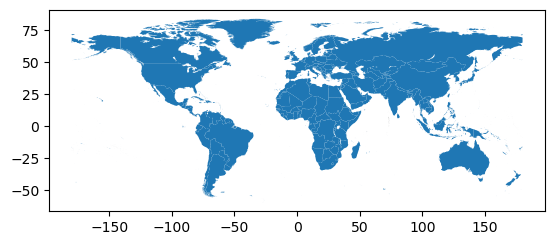

In [53]:
countries = gpd.read_file('ne_10m_admin_0_countries_lakes/ne_10m_admin_0_countries_lakes.shp')
countries = countries[countries['NAME']!='Antarctica']
countries.plot()

In [54]:
countries.to_file('countries.geojson', driver='GeoJSON')

In [55]:
pts = pd.read_csv('mapdata.csv')

In [56]:
pts.head()

,name,hometown,hometown_lat,hometown_lon,undergrad,ug_lat,ug_lon
0,Nathan L.,San Diego,32.705583,-117.151322,UC Santa Cruz,36.990491,-122.058533
1,Yogi P.,Irvine,33.685811,-117.827111,Arizona State University,33.422899,-111.927916
2,Chloe A.,Pasadena,39.150565,-76.551271,Duke Kunshan University,31.415877,120.901438
3,Isaac T.,Singapore,1.435508,103.801006,University of Oxford,51.756917,-1.254475
4,Lauryn C.,Singapore,1.309032,103.805035,University College London,51.524519,-0.134029


In [57]:
h_geom = gpd.points_from_xy(pts["hometown_lon"], pts["hometown_lat"])
u_geom = gpd.points_from_xy(pts['ug_lon'], pts['ug_lat'])

In [58]:
gdf = gpd.GeoDataFrame(pts, geometry=h_geom, crs='EPSG:4326')

<Axes: >

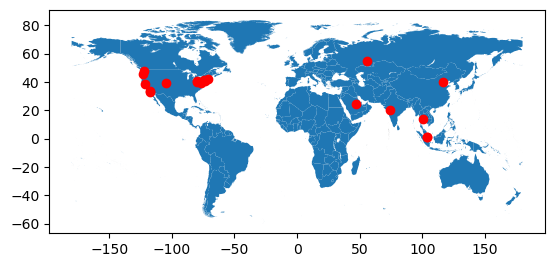

In [59]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
countries.plot(ax=ax)
gdf.plot(ax=ax, color='red')

In [60]:
gdf['ug_geometry'] = gpd.GeoSeries(u_geom, crs='EPSG:4326')

<Axes: >

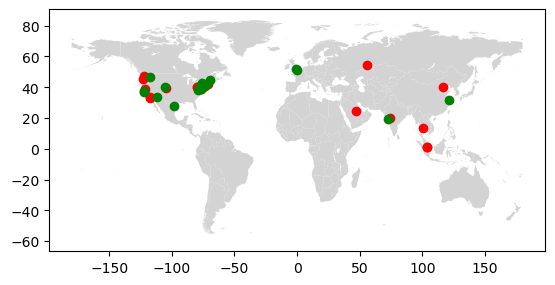

In [61]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
countries.plot(ax=ax, color='lightgray')
gdf.plot(ax=ax, color='red')
gdf['ug_geometry'].plot(ax=ax, color='green')

In [62]:
from shapely.geometry import LineString 

lines = [
    LineString([start, end])
    for start, end in zip(gdf["geometry"], gdf["ug_geometry"])
]

gdf['line_geom'] = gpd.GeoSeries(lines, crs=gdf.crs)

<Axes: >

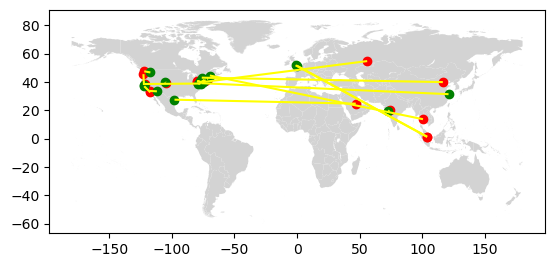

In [63]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
countries.plot(ax=ax, color='lightgray')
gdf.plot(ax=ax, color='red')
gdf['ug_geometry'].plot(ax=ax, color='green')
gdf['line_geom'].plot(ax=ax, color='yellow')

In [64]:
gdf = gdf.rename_geometry("h_geometry")

In [65]:
gdf = gdf.rename(columns={'line_geom':'line_geometry'})

In [66]:
geom_cols = [c for c in gdf.columns if gdf[c].dtype == "geometry"]

for col in geom_cols:
    others = [c for c in geom_cols if c != col]
    out = gdf.drop(columns=others).set_geometry(col)
    out = out.to_crs(4326) 
    out.to_file(f"{col}.geojson", driver="GeoJSON")

In [67]:
import geopandas as gpd
from shapely.geometry import Point

penn = gpd.GeoDataFrame(
    {"name": ["Penn"]},      
    geometry=[Point(-75.19282958975501, 39.952267207286575)],
    crs="EPSG:4326",
)

<Axes: >

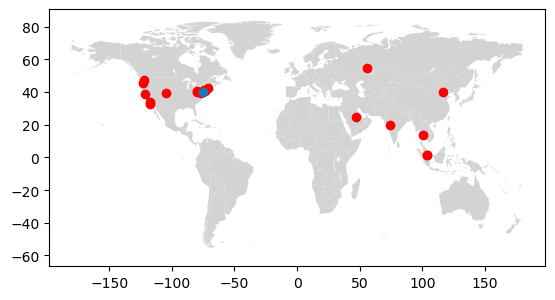

In [68]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
countries.plot(ax=ax, color='lightgray')
gdf.plot(ax=ax, color='red')
penn.plot(ax=ax)

In [69]:
gdf = gdf.rename_geometry("geometry")

In [70]:
gdf = pd.concat([gdf,penn], ignore_index=True)

In [71]:
origin_idx = gdf.index[gdf["name"] == "Penn"][0]

In [73]:
origin = gdf.geometry.loc[origin_idx]
others = gdf.drop(index=origin_idx)

lines = gpd.GeoDataFrame(
    {"from_idx": origin_idx, "to_idx": others.index},
    geometry=[LineString([origin, p]) for p in others.geometry],
    crs=gdf.crs,
)

<Axes: >

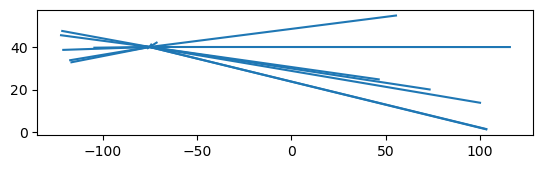

In [75]:
lines.plot()

In [78]:
penn.to_file('penn.geojson', driver='GeoJSON')

In [79]:
lines.to_file('lines.geojson', driver='GeoJSON')